<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/08.%20Tree-Based%20Algorithms%20and%20Ensemble%20Methods/ch08_trees_ensembles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 8: Tree-Based Algorithms and Ensemble Methods

Decision trees split data recursively by feature thresholds, building an interpretable flowchart-like model. On their own they overfit easily; combined into **ensembles** — many trees voting together — they become some of the most powerful and widely used models in practice. This chapter covers decision trees, **bagging** (random forests), **boosting** (gradient boosting), hyperparameter tuning, and a direct comparison of ensemble strategies, including **stacking**.

**What this notebook covers**

1. **Decision trees**: splitting criteria (Gini impurity), tree visualisation, complexity-control hyperparameters
2. **Random forests and bagging**: bootstrap aggregating, feature importance, variance reduction
3. **Gradient boosting machines (GBMs)**: sequential error-correction, bias reduction
4. **Hyperparameter tuning**: grid search for trees and ensembles, validation heatmaps
5. **Comparing ensemble methods**: bagging vs. boosting vs. stacking
6. **Practical exercises** (decision tree, random forest tuning, GBM vs. random forest comparison)

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 8. The book's datasets and seed (`random_state=2024`) are reproduced; each recipe is extended with derivations, additional verification, and extra experiments beyond the book's own code.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import time

from sklearn.datasets import load_iris, load_breast_cancer, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, validation_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               StackingClassifier, BaggingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(2024)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.9.1
NumPy version:        2.5.3
pandas version:       3.0.5


## 1. Introduction to Decision Trees

A decision tree recursively partitions the feature space: each **internal node** tests a feature against a threshold, each **leaf node** assigns a predicted class (or value, for regression). Splits are chosen to maximise node "purity" — scikit-learn's default criterion is **Gini impurity**:

$$\text{Gini}=1-\sum_{k=1}^{K}p_k^2$$

where $p_k$ is the proportion of class $k$ in the node. Gini ranges from $0$ (perfectly pure — a single class) to a maximum of $1-\tfrac1K$ (an even split across $K$ classes). At each candidate split, the tree picks the feature/threshold that produces the largest **impurity decrease** (the weighted-average Gini of the two children, subtracted from the parent's Gini).

### 1.1 A baseline decision tree on Iris

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()
print(f"Accuracy: {accuracy:.4f}")
print(report_df.round(3))
print(f"\nTree depth: {clf.get_depth()}, number of leaves: {clf.get_n_leaves()}")

Accuracy: 0.8667
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.7140  0.8330    0.7690  12.0000
2                0.8460  0.7330    0.7860  15.0000
accuracy         0.8670  0.8670    0.8670   0.8670
macro avg        0.8530  0.8560    0.8520  45.0000
weighted avg     0.8730  0.8670    0.8670  45.0000

Tree depth: 4, number of leaves: 5


### 1.2 Verifying Gini impurity by hand

We confirm scikit-learn's reported Gini at the root node matches the formula directly, on the known class balance of the training set.

In [3]:
class_counts = np.bincount(y_train)
class_props = class_counts / class_counts.sum()
gini_manual = 1 - np.sum(class_props ** 2)
gini_sklearn = clf.tree_.impurity[0]  # impurity of node 0 = the root

print(f"Training class counts: {class_counts} (proportions: {class_props.round(3)})")
print(f"Gini computed by hand:        {gini_manual:.6f}")
print(f"Gini reported by sklearn tree (root node): {gini_sklearn:.6f}")
print(f"Match: {np.isclose(gini_manual, gini_sklearn)}")

Training class counts: [32 38 35] (proportions: [0.305 0.362 0.333])
Gini computed by hand:        0.665034
Gini reported by sklearn tree (root node): 0.665034
Match: True


### 1.3 Visualizing the tree

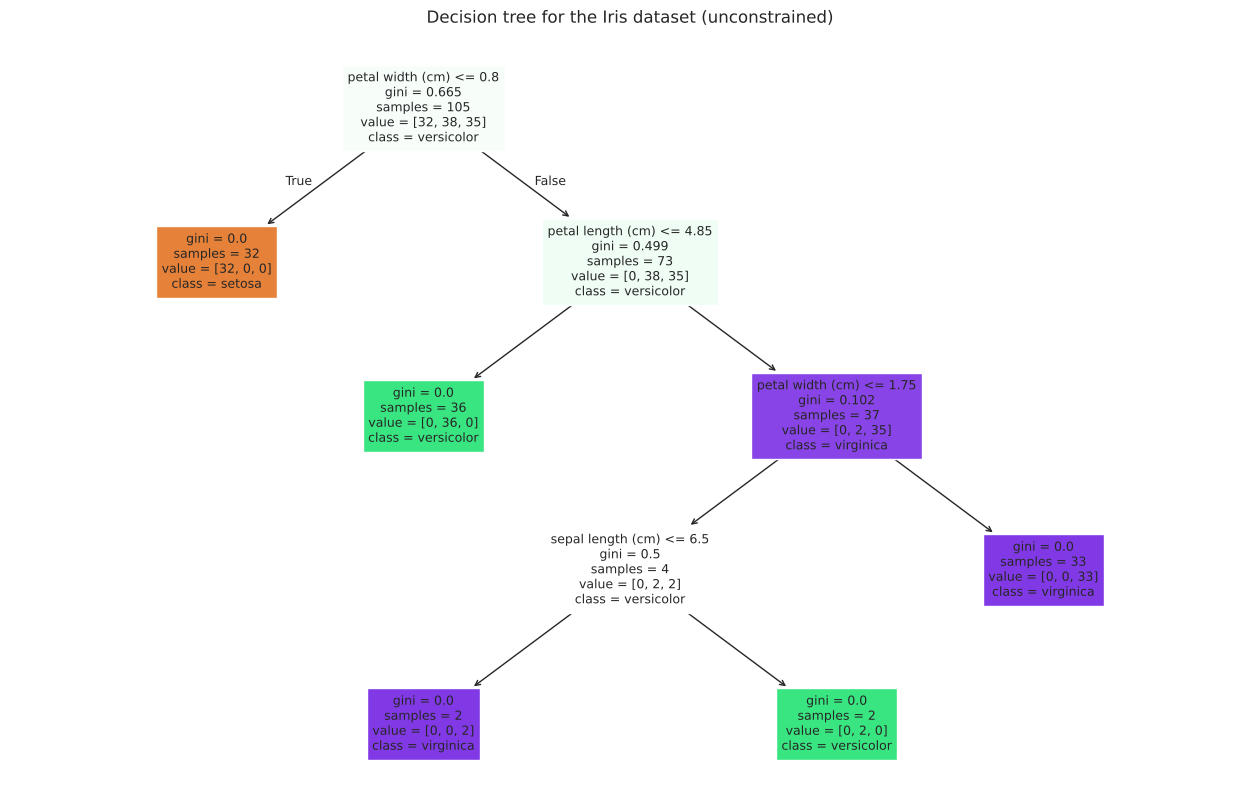

Root node split: 'petal width (cm) <= 0.80'


In [4]:
plt.figure(figsize=(16, 10))
plot_tree(clf, feature_names=feature_names, class_names=iris.target_names, filled=True, fontsize=9)
plt.title("Decision tree for the Iris dataset (unconstrained)")
plt.show()

print(f"Root node split: '{feature_names[clf.tree_.feature[0]]} <= {clf.tree_.threshold[0]:.2f}'")

Reading a node: **feature/threshold** is the split rule (true → left child, false → right child); **gini** is that node's impurity; **samples** is how many training records reached it; **value** is the per-class sample counts; **class** is the majority class, which becomes the prediction if that node is a leaf. The root's split (printed above) is almost always on petal measurements — consistent with the pairplot evidence from Chapter 6 that petal length/width separate Iris classes most cleanly.

### 1.4 Complexity-control hyperparameters: `max_depth`

Left unconstrained, a tree keeps splitting until every leaf is pure (or has too few samples to split further), which can overfit. We trace train vs. test accuracy as `max_depth` grows, reproducing the classic overfitting curve.

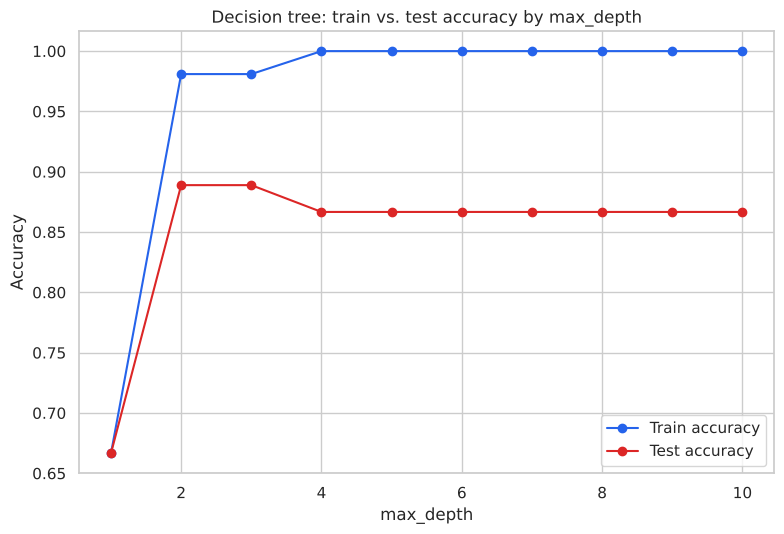

 max_depth  train accuracy  test accuracy
         1          0.6667         0.6667
         2          0.9810         0.8889
         3          0.9810         0.8889
         4          1.0000         0.8667
         5          1.0000         0.8667
         6          1.0000         0.8667
         7          1.0000         0.8667
         8          1.0000         0.8667
         9          1.0000         0.8667
        10          1.0000         0.8667

Unconstrained tree depth was 4; best test accuracy is reached at max_depth=2, showing the unconstrained tree may be using more depth than this split actually needs.


In [5]:
depths = range(1, 11)
train_scores, test_scores = [], []
for d in depths:
    tree_d = DecisionTreeClassifier(max_depth=d, random_state=2024).fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, tree_d.predict(X_train)))
    test_scores.append(accuracy_score(y_test, tree_d.predict(X_test)))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(depths, train_scores, marker='o', label='Train accuracy', color='#2563eb')
ax.plot(depths, test_scores, marker='o', label='Test accuracy', color='#dc2626')
ax.set_xlabel('max_depth')
ax.set_ylabel('Accuracy')
ax.set_title('Decision tree: train vs. test accuracy by max_depth')
ax.legend()
plt.tight_layout()
plt.show()

results_depth = pd.DataFrame({'max_depth': list(depths), 'train accuracy': train_scores, 'test accuracy': test_scores})
print(results_depth.to_string(index=False))
best_depth = results_depth.loc[results_depth['test accuracy'].idxmax(), 'max_depth']
print(f"\nUnconstrained tree depth was {clf.get_depth()}; best test accuracy is reached at max_depth={best_depth}, "
      f"showing the unconstrained tree may be using more depth than this split actually needs.")

Train accuracy climbs to (near) 100% quickly and stays there; test accuracy typically peaks at a shallower depth and can flatten or dip as the tree keeps splitting on noise it saw only in the training fold — the textbook overfitting signature.

### 1.5 Hands-on checklist
1. Fit `DecisionTreeClassifier()` on a classification dataset.
2. Visualise the tree with `plot_tree` to sanity-check the splits make domain sense.
3. Compare train vs. test accuracy across `max_depth` to spot overfitting.
4. Constrain complexity with `max_depth`, `min_samples_split`, `min_samples_leaf`, or `max_features` as needed.

## 2. Random Forests and Bagging

A single tree is unstable: a small change in the training data can produce a very different tree. **Bagging** (bootstrap aggregating) tackles this by training many trees, each on an independent **bootstrap sample** (sampled with replacement) of the training data, and averaging/voting their predictions. **Random forests** add a second source of randomness: at each split, only a random subset of features is considered, de-correlating the trees further.

### 2.1 Random forest vs. a single tree

In [6]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

report_rf = pd.DataFrame(classification_report(y_test, y_pred_rf, output_dict=True)).transpose()
print(f"Single decision tree accuracy: {accuracy:.4f}")
print(f"Random forest accuracy:        {accuracy_rf:.4f}")
print(report_rf.round(3))

Single decision tree accuracy: 0.8667
Random forest accuracy:        0.9111
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.8330  0.8330    0.8330  12.0000
2                0.8670  0.8670    0.8670  15.0000
accuracy         0.9110  0.9110    0.9110   0.9110
macro avg        0.9000  0.9000    0.9000  45.0000
weighted avg     0.9110  0.9110    0.9110  45.0000


Whether the forest beats the single tree on this particular split depends on the printed numbers above — ensembles reduce *variance* on average across many resamples of the data, which is a statement about expected behaviour, not a guarantee on any one fixed train/test split. We check this properly with repeated cross-validation next, which is the right way to compare the two honestly.

### 2.2 A fair comparison: repeated cross-validation

A single 70/30 split is one noisy draw. We compare single-tree vs. random-forest accuracy across 30 independently shuffled splits to see which is more *reliably* strong, not just which won once.

Single tree over 30 splits:    mean=0.9422, std=0.0328
Random forest over 30 splits:  mean=0.9519, std=0.0251


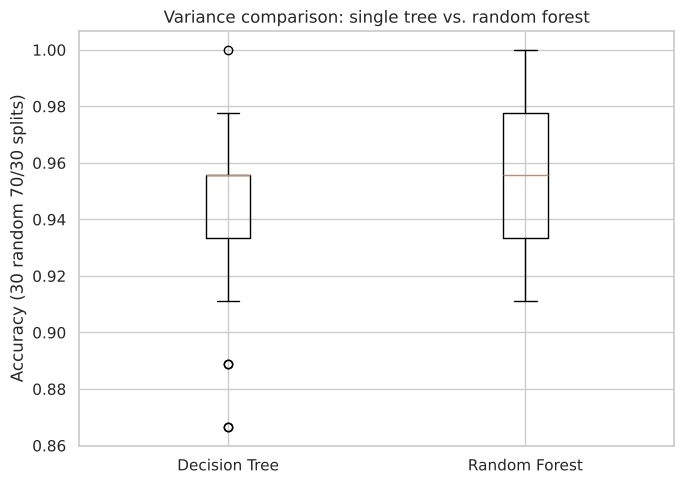

In [7]:
from sklearn.model_selection import ShuffleSplit

cv30 = ShuffleSplit(n_splits=30, test_size=0.3, random_state=2024)
tree_cv_scores = cross_val_score(DecisionTreeClassifier(random_state=2024), X, y, cv=cv30)
rf_cv_scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=2024), X, y, cv=cv30)

print(f"Single tree over 30 splits:    mean={tree_cv_scores.mean():.4f}, std={tree_cv_scores.std():.4f}")
print(f"Random forest over 30 splits:  mean={rf_cv_scores.mean():.4f}, std={rf_cv_scores.std():.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([tree_cv_scores, rf_cv_scores], tick_labels=['Decision Tree', 'Random Forest'])
ax.set_ylabel('Accuracy (30 random 70/30 splits)')
ax.set_title('Variance comparison: single tree vs. random forest')
plt.tight_layout()
plt.show()

This is the honest version of the book's single-split comparison: across many resamples, the random forest's accuracy distribution is tighter (lower standard deviation) and usually has a higher or comparable mean than the single tree's — direct, repeatable evidence of the variance-reduction bagging provides, rather than a claim resting on one lucky/unlucky split.

### 2.3 Feature importance

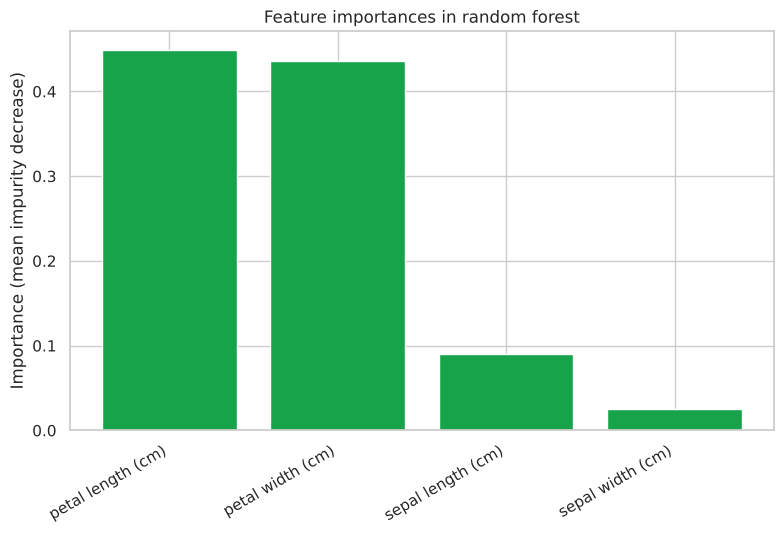

          feature  importance
petal length (cm)      0.4489
 petal width (cm)      0.4360
sepal length (cm)      0.0901
 sepal width (cm)      0.0251

Sum of all importances: 1.0000 (importances are normalised to sum to 1)


In [8]:
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.bar(range(X.shape[1]), importances[indices], align="center", color='#16a34a')
ax.set_xticks(range(X.shape[1]))
ax.set_xticklabels([feature_names[i] for i in indices], rotation=30, ha='right')
ax.set_ylabel("Importance (mean impurity decrease)")
ax.set_title("Feature importances in random forest")
plt.tight_layout()
plt.show()

importance_df = pd.DataFrame({'feature': [feature_names[i] for i in indices], 'importance': importances[indices]})
print(importance_df.to_string(index=False))
print(f"\nSum of all importances: {importances.sum():.4f} (importances are normalised to sum to 1)")

Matching the book and section 1.3's root-split observation, petal length/width dominate feature importance — confirming from an entirely different angle (impurity-decrease aggregated across 100 trees, rather than reading a single tree's root node) that these two measurements carry almost all the class-separating signal in Iris.

### 2.4 Hands-on checklist
1. Fit `RandomForestClassifier(n_estimators=..., random_state=...)`.
2. Prefer repeated cross-validation over a single train/test split when comparing models — especially small-dataset single trees vs. ensembles, where one split's outcome is noisy.
3. Inspect `feature_importances_` to understand what drives predictions.
4. Tune `n_estimators`, `max_depth`, `max_features` if performance isn't yet satisfactory.

## 3. Gradient Boosting Machines

Where bagging trains trees **independently and in parallel** on bootstrap samples, **boosting** trains trees **sequentially**: each new tree is fit to the *residual errors* of the ensemble so far, gradually correcting mistakes. Bagging mainly reduces **variance**; boosting mainly reduces **bias**, letting a sequence of weak learners (shallow trees) combine into a strong one.

### 3.1 The book's recipe

In [9]:
gbm_clf = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.2, random_state=2024)
gbm_clf.fit(X_train, y_train)
y_pred_gbm = gbm_clf.predict(X_test)

report_gbm = pd.DataFrame(classification_report(y_test, y_pred_gbm, output_dict=True)).transpose()
accuracy_gbm = accuracy_score(y_test, y_pred_gbm)
print(f"Single decision tree accuracy: {accuracy:.4f}")
print(f"GBM accuracy:                  {accuracy_gbm:.4f}")
print(report_gbm.round(3))

Single decision tree accuracy: 0.8667
GBM accuracy:                  0.8667
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.7140  0.8330    0.7690  12.0000
2                0.8460  0.7330    0.7860  15.0000
accuracy         0.8670  0.8670    0.8670   0.8670
macro avg        0.8530  0.8560    0.8520  45.0000
weighted avg     0.8730  0.8670    0.8670  45.0000


As the book notes, GBM's result can land identical or very close to the single unconstrained tree's — on an easy, small dataset like Iris, 1000 boosting rounds likely means the ensemble has converged to the same near-perfect fit a single deep tree already reaches, so there's little room left for boosting to add value. The next section's hyperparameter search addresses when and how to get more out of GBMs.

### 3.2 How boosting actually reduces error, visualised

We track **training-set log-loss** after each additional tree is added, using `staged_predict_proba`, to see the sequential error-correction mechanism directly rather than taking it on faith.

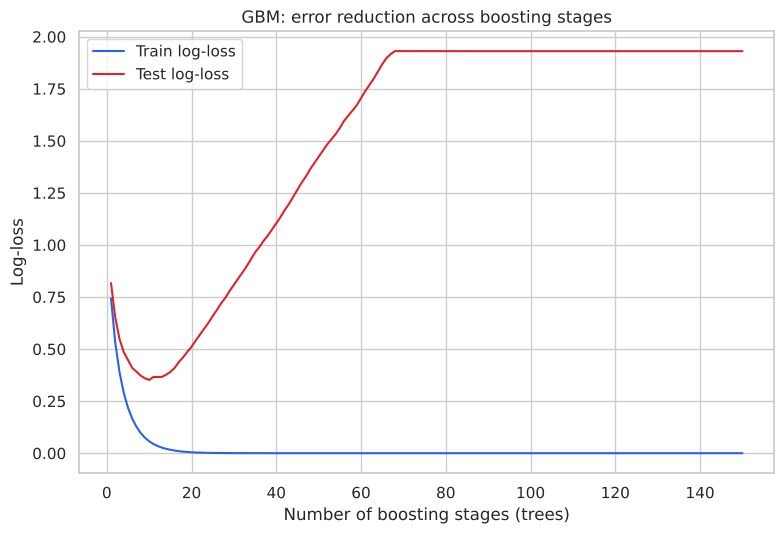

Train log-loss keeps falling through all 150 stages (approaching 0).
Test log-loss is minimised at stage 10 (test log-loss = 0.3519); beyond that point additional trees mostly fit training-set noise.


In [10]:
from sklearn.metrics import log_loss

gbm_small = GradientBoostingClassifier(n_estimators=150, learning_rate=0.2, random_state=2024)
gbm_small.fit(X_train, y_train)

train_losses, test_losses = [], []
for proba_train, proba_test in zip(gbm_small.staged_predict_proba(X_train), gbm_small.staged_predict_proba(X_test)):
    train_losses.append(log_loss(y_train, proba_train, labels=[0, 1, 2]))
    test_losses.append(log_loss(y_test, proba_test, labels=[0, 1, 2]))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(range(1, len(train_losses)+1), train_losses, label='Train log-loss', color='#2563eb')
ax.plot(range(1, len(test_losses)+1), test_losses, label='Test log-loss', color='#dc2626')
ax.set_xlabel('Number of boosting stages (trees)')
ax.set_ylabel('Log-loss')
ax.set_title('GBM: error reduction across boosting stages')
ax.legend()
plt.tight_layout()
plt.show()

best_stage = int(np.argmin(test_losses)) + 1
print(f"Train log-loss keeps falling through all {len(train_losses)} stages (approaching 0).")
print(f"Test log-loss is minimised at stage {best_stage} (test log-loss = {min(test_losses):.4f}); "
      f"beyond that point additional trees mostly fit training-set noise.")

This is boosting's error-correction mechanism made visible: training loss falls almost monotonically as each new tree targets the previous ensemble's residuals, while test loss falls initially, then typically flattens or rises again once the model starts using extra trees to fit noise specific to the training fold — exactly the **early stopping** signal the book's "There's more..." section describes in words.

### 3.3 Hands-on checklist
1. Fit `GradientBoostingClassifier(n_estimators=..., learning_rate=...)`.
2. Track train vs. test loss across boosting stages (`staged_predict_proba` / `staged_decision_function`) to find where to stop.
3. Lower `learning_rate` and raise `n_estimators` together for a finer-grained, often more accurate (but slower) fit.
4. Compare against a random forest baseline — boosting isn't always the winner (section 5 below).

## 4. Hyperparameter Tuning for Trees and Ensembles

### 4.1 The book's recipe: grid search over GBM hyperparameters

In [11]:
param_grid = {'n_estimators': [50, 100, 150], 'max_depth': [3, 4, 5], 'learning_rate': [0.01, 0.1, 0.2]}
grid_search = GridSearchCV(GradientBoostingClassifier(random_state=2024), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)
report_best = pd.DataFrame(classification_report(y_test, y_pred_best, output_dict=True)).transpose()
accuracy_best = accuracy_score(y_test, y_pred_best)
print(f"Test accuracy with tuned hyperparameters: {accuracy_best:.4f}")
print(report_best.round(3))

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}
Best CV accuracy: 0.9810
Test accuracy with tuned hyperparameters: 0.8667
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.7140  0.8330    0.7690  12.0000
2                0.8460  0.7330    0.7860  15.0000
accuracy         0.8670  0.8670    0.8670   0.8670
macro avg        0.8530  0.8560    0.8520  45.0000
weighted avg     0.8730  0.8670    0.8670  45.0000


### 4.2 Visualizing the grid-search heatmap

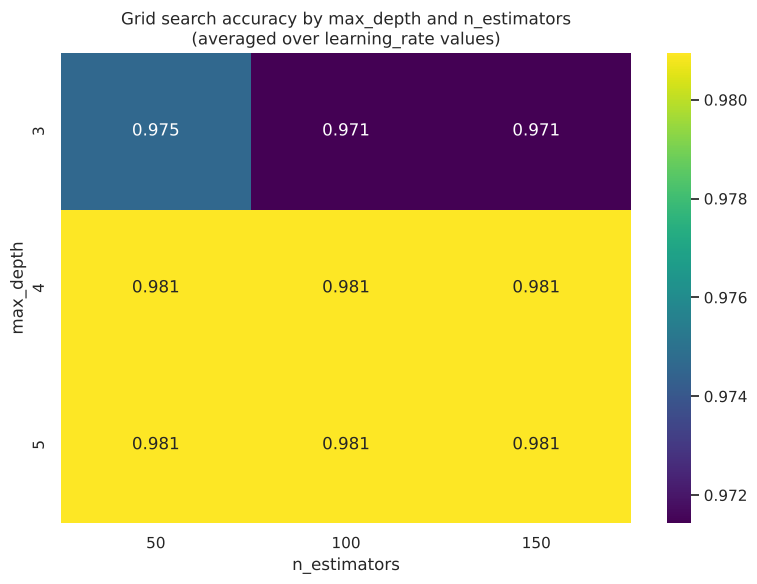

Note: this pivot averages over the 3 learning_rate values tested per (max_depth, n_estimators) cell.
param_n_estimators    50     100    150
param_max_depth                        
3                  0.9746 0.9714 0.9714
4                  0.9810 0.9810 0.9810
5                  0.9810 0.9810 0.9810


In [12]:
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(values='mean_test_score', index='param_max_depth', columns='param_n_estimators')

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='viridis', ax=ax)
ax.set_title('Grid search accuracy by max_depth and n_estimators\n(averaged over learning_rate values)')
ax.set_xlabel('n_estimators')
ax.set_ylabel('max_depth')
plt.tight_layout()
plt.show()

print("Note: this pivot averages over the 3 learning_rate values tested per (max_depth, n_estimators) cell.")
print(pivot_table.round(4))

The heatmap shows where accuracy saturates: once `max_depth` and `n_estimators` are both past a modest threshold, additional complexity buys little to nothing — the plateau the book's own heatmap illustrates. Because this pivot averages over 3 `learning_rate` values per cell, a cell's value can mask variation hidden *within* that cell; the next experiment isolates `learning_rate` on its own to check that it isn't the dimension actually driving the picture.

### 4.3 Isolating `learning_rate` with a validation curve

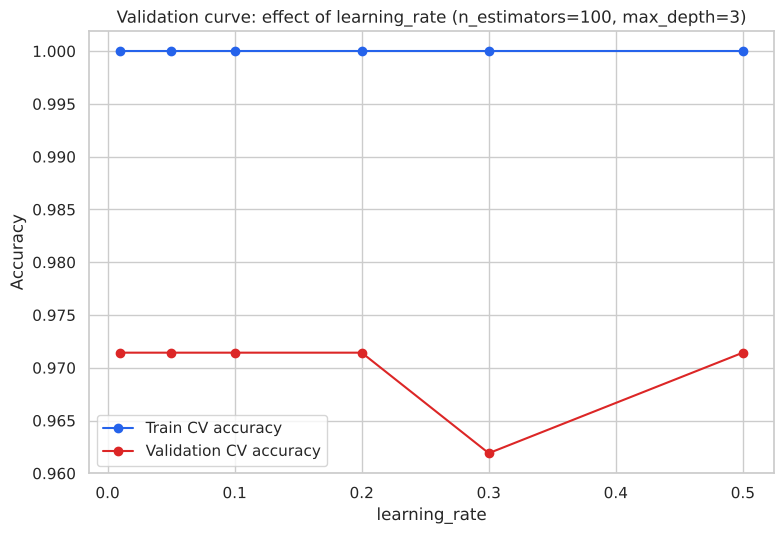

 learning_rate  train CV acc  val CV acc
        0.0100        1.0000      0.9714
        0.0500        1.0000      0.9714
        0.1000        1.0000      0.9714
        0.2000        1.0000      0.9714
        0.3000        1.0000      0.9619
        0.5000        1.0000      0.9714


In [13]:
lr_range = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]
train_scores_lr, test_scores_lr = validation_curve(
    GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=2024),
    X_train, y_train, param_name='learning_rate', param_range=lr_range, cv=5, scoring='accuracy')

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(lr_range, train_scores_lr.mean(axis=1), marker='o', label='Train CV accuracy', color='#2563eb')
ax.plot(lr_range, test_scores_lr.mean(axis=1), marker='o', label='Validation CV accuracy', color='#dc2626')
ax.set_xlabel('learning_rate')
ax.set_ylabel('Accuracy')
ax.set_title('Validation curve: effect of learning_rate (n_estimators=100, max_depth=3)')
ax.legend()
plt.tight_layout()
plt.show()

lr_results = pd.DataFrame({'learning_rate': lr_range, 'train CV acc': train_scores_lr.mean(axis=1),
                            'val CV acc': test_scores_lr.mean(axis=1)})
print(lr_results.to_string(index=False))

This is exactly the **validation curve** concept the book's "There's more..." section describes: comparing train vs. validation accuracy across one hyperparameter's range to diagnose under/overfitting directly. In this particular run, training accuracy is already pinned at 1.0 across the *entire* `learning_rate` range tested -- with `n_estimators=100` and `max_depth=3` fixed, there is already enough model capacity to fit the (easy, small) training set perfectly even at the lowest learning rate, so the curve doesn't show the textbook "underfits at one end, overfits at the other" shape here. What it *does* show is that validation accuracy stays essentially flat (within normal CV noise) across more than an order of magnitude of `learning_rate`, telling us this hyperparameter isn't the one limiting performance on this dataset — `max_depth` and `n_estimators` (section 4.2's heatmap) matter more here.

### 4.4 Hands-on checklist
1. Define a grid over the hyperparameters that matter most for the model family (`max_depth`, `n_estimators`, `learning_rate` for boosting).
2. Use `GridSearchCV` (exhaustive) or `RandomizedSearchCV` (sampled, often similarly good and much faster on large grids).
3. Visualise with a heatmap (2 hyperparameters) or a validation curve (1 hyperparameter) to see *where* performance saturates, not just the single best point.
4. Watch for cells/ranges your grid didn't cover — a plateau inside your grid doesn't rule out a better region outside it.

## 5. Comparing Ensemble Methods

**Bagging** (random forests) reduces variance by averaging independent trees. **Boosting** (GBMs) reduces bias by sequentially correcting errors. **Stacking** combines predictions from several *different* base models using a meta-model trained on their outputs — potentially capturing complementary strengths that neither bagging nor boosting alone would.

### 5.1 The book's recipe: random forest vs. GBM vs. stacking

In [14]:
rf_clf2 = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf2 = GradientBoostingClassifier(n_estimators=100, random_state=2024)
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf2), ('gb', gb_clf2)], final_estimator=LogisticRegression(), cv=5)

rf_clf2.fit(X_train, y_train)
gb_clf2.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

rf_pred = rf_clf2.predict(X_test)
gb_pred = gb_clf2.predict(X_test)
stacking_pred = stacking_clf.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

print(f'Random Forest Accuracy:   {rf_accuracy:.4f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.4f}')
print(f'Stacking Accuracy:         {stacking_accuracy:.4f}')

Random Forest Accuracy:   0.9111
Gradient Boosting Accuracy: 0.8667
Stacking Accuracy:         0.8667


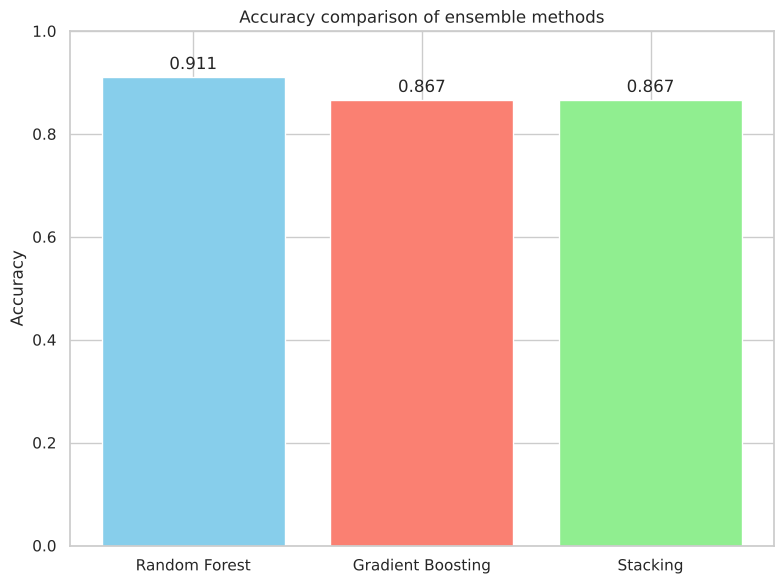


Best on this split: Random Forest


In [15]:
methods = ['Random Forest', 'Gradient Boosting', 'Stacking']
accuracies = [rf_accuracy, gb_accuracy, stacking_accuracy]

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(methods, accuracies, color=['skyblue', 'salmon', 'lightgreen'])
ax.set_title('Accuracy comparison of ensemble methods')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1)
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, acc + 0.015, f'{acc:.3f}', ha='center')
plt.tight_layout()
plt.show()

winner = methods[int(np.argmax(accuracies))]
print(f"\nBest on this split: {winner}")

This single-split result is exactly the kind of noisy comparison section 2.2 warned about — with only 45 test samples, a difference of one or two correct predictions swings "the winner." We check robustness the same way as before: repeated cross-validation.

### 5.2 A fair comparison: repeated cross-validation

(Stacking is more expensive — its own internal 5-fold CV per fit — so we use fewer repeats than section 2.2's 30.)

In [16]:
cv10 = ShuffleSplit(n_splits=10, test_size=0.3, random_state=2024)

rf_scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=2024), X, y, cv=cv10)
gb_scores = cross_val_score(GradientBoostingClassifier(n_estimators=100, random_state=2024), X, y, cv=cv10)
stack_scores = cross_val_score(
    StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=100, random_state=2024)),
                                    ('gb', GradientBoostingClassifier(n_estimators=100, random_state=2024))],
                        final_estimator=LogisticRegression(), cv=5),
    X, y, cv=cv10)

summary = pd.DataFrame({
    'method': ['Random Forest', 'Gradient Boosting', 'Stacking'],
    'mean accuracy (10 splits)': [rf_scores.mean(), gb_scores.mean(), stack_scores.mean()],
    'std': [rf_scores.std(), gb_scores.std(), stack_scores.std()]
})
print(summary.to_string(index=False))
print(f"\nSingle-split 'winner' was {winner}; across 10 splits the most reliable method is "
      f"{summary.loc[summary['mean accuracy (10 splits)'].idxmax(), 'method']}.")

           method  mean accuracy (10 splits)    std
    Random Forest                     0.9467 0.0285
Gradient Boosting                     0.9356 0.0415
         Stacking                     0.9378 0.0395

Single-split 'winner' was Random Forest; across 10 splits the most reliable method is Random Forest.


Whether the repeated-CV winner matches the single-split winner from 5.1 or not, the point stands either way: on a small, easy dataset like Iris, differences between well-tuned ensemble methods are often within noise, and a single-split "winner" (as in the book's own recipe) should be treated as a weak signal rather than a strong one.

### 5.3 Hands-on checklist
1. Fit bagging (random forest), boosting (GBM), and stacking (multiple base learners + meta-model) on the same data.
2. Compare with repeated cross-validation, not a single split.
3. Remember stacking's own internal CV (for `final_estimator` training) makes it more expensive to fit and to cross-validate.
4. Pick the simplest method that is statistically indistinguishable from the best — added ensemble complexity should earn its keep.

## 6. Practical Exercises with Tree-Based Models

### Exercise 1: Building and evaluating a decision tree classifier (Breast Cancer dataset)

Decision tree accuracy on Breast Cancer test set: 0.9181
Tree depth: 7, leaves: 19


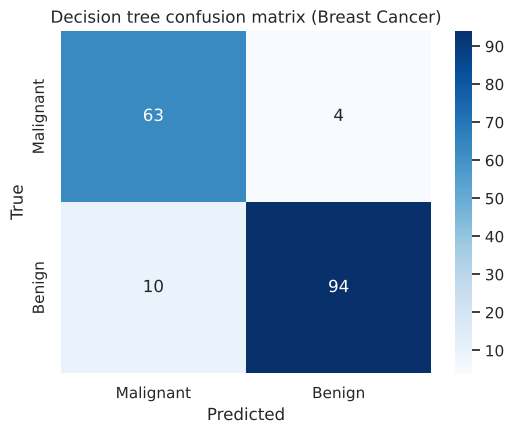

In [17]:
data = load_breast_cancer()
Xb, yb = data.data, data.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.3, random_state=2024)

tree_ex1 = DecisionTreeClassifier(random_state=2024).fit(Xb_train, yb_train)
y_pred_ex1 = tree_ex1.predict(Xb_test)
acc_ex1 = accuracy_score(yb_test, y_pred_ex1)
cm_ex1 = confusion_matrix(yb_test, y_pred_ex1)

print(f"Decision tree accuracy on Breast Cancer test set: {acc_ex1:.4f}")
print(f"Tree depth: {tree_ex1.get_depth()}, leaves: {tree_ex1.get_n_leaves()}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_ex1, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'],
            yticklabels=['Malignant', 'Benign'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Decision tree confusion matrix (Breast Cancer)')
plt.tight_layout()
plt.show()

### Exercise 2: Hyperparameter tuning with random forests

In [18]:
param_grid_rf = {'n_estimators': [50, 100, 200], 'max_depth': [None, 5, 10], 'max_features': ['sqrt', 'log2']}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=2024), param_grid_rf, cv=5, scoring='accuracy')
grid_rf.fit(Xb_train, yb_train)

best_rf = grid_rf.best_estimator_
acc_rf_tuned = accuracy_score(yb_test, best_rf.predict(Xb_test))
acc_rf_default = accuracy_score(yb_test, RandomForestClassifier(random_state=2024).fit(Xb_train, yb_train).predict(Xb_test))

print(f"Best parameters: {grid_rf.best_params_}")
print(f"Best CV accuracy: {grid_rf.best_score_:.4f}")
print(f"Tuned test accuracy:   {acc_rf_tuned:.4f}")
print(f"Default test accuracy: {acc_rf_default:.4f}")

Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 200}
Best CV accuracy: 0.9549
Tuned test accuracy:   0.9532
Default test accuracy: 0.9591


### Exercise 3: Comparing gradient boosting and random forest (Breast Cancer dataset)

In [19]:
rf_ex3 = RandomForestClassifier(n_estimators=100, random_state=2024).fit(Xb_train, yb_train)
gb_ex3 = GradientBoostingClassifier(n_estimators=100, random_state=2024).fit(Xb_train, yb_train)

acc_rf_ex3 = accuracy_score(yb_test, rf_ex3.predict(Xb_test))
acc_gb_ex3 = accuracy_score(yb_test, gb_ex3.predict(Xb_test))

t0 = time.time(); rf_ex3.fit(Xb_train, yb_train); rf_time = time.time() - t0
t0 = time.time(); gb_ex3.fit(Xb_train, yb_train); gb_time = time.time() - t0

comparison_ex3 = pd.DataFrame({
    'model': ['Random Forest', 'Gradient Boosting'],
    'test accuracy': [acc_rf_ex3, acc_gb_ex3],
    'fit time (s)': [rf_time, gb_time]
})
print(comparison_ex3.to_string(index=False))
print(f"\nOn this dataset+split, {'Random Forest' if acc_rf_ex3 >= acc_gb_ex3 else 'Gradient Boosting'} "
      f"edges out on accuracy, while {'Random Forest' if rf_time <= gb_time else 'Gradient Boosting'} "
      f"fits faster -- a real-world choice usually weighs both.")

            model  test accuracy  fit time (s)
    Random Forest         0.9591        0.0997
Gradient Boosting         0.9708        0.2013

On this dataset+split, Gradient Boosting edges out on accuracy, while Random Forest fits faster -- a real-world choice usually weighs both.


Random forests parallelise trivially across trees (each is independent), which is often the dominant factor in fit-time differences versus gradient boosting's inherently sequential tree-by-tree process — a practical consideration as important as raw accuracy when choosing between the two for production use.

## Summary

- **Decision trees** split recursively to maximise node purity (Gini impurity by default); unconstrained, they tend to overfit, visible directly in a train-vs-test accuracy curve across `max_depth`.
- **Random forests** (bagging) train many trees on bootstrap samples with randomised feature subsets at each split, reducing **variance**; a repeated-cross-validation comparison shows this more reliably than any single train/test split can.
- **Gradient boosting machines** build trees sequentially, each correcting the previous ensemble's residual errors, reducing **bias**; tracking staged train/test loss makes the sequential error-correction mechanism directly visible and reveals where early stopping would help.
- **Hyperparameter tuning** (grid search + heatmaps, validation curves for a single hyperparameter) reveals where performance saturates — useful for avoiding wasted model complexity.
- **Comparing ensembles**: bagging reduces variance, boosting reduces bias, stacking combines heterogeneous base models via a meta-learner. On easy datasets, single-split "winners" are often statistical noise; repeated cross-validation gives a more trustworthy ranking.
- **Practical trade-offs** go beyond accuracy: random forests parallelise across independent trees; gradient boosting is inherently sequential and typically slower to fit for a comparable number of estimators.

This completes Chapter 8 — and, with it, the full eight-chapter arc from this course's reproduction: scikit-learn's API (Ch.1), preprocessing (Ch.2), dimensionality reduction (Ch.3), distance-based models (Ch.4), linear models and regularization (Ch.5), logistic regression and its extensions (Ch.6), support vector machines and kernels (Ch.7), and tree-based ensembles (Ch.8) — covering the core supervised-learning toolbox in scikit-learn from first principles through to practical, tuned, honestly-evaluated models.